# 18 — Idle tests T0–T5 on the H2-1E emulator

The questions, runs and decision rules were fixed before any shots (`scratchpad.md`,
`config/idle_tests.json`). Every program was built with pytket + pytket-qir and sent with explicit
emulator options (stabilizer simulator, noise on, `no_opt`; dephasing flags **on** unless marked
**off**). T1 needed no runs, and T6 (real H2-1) was not run.

| test | question |
| --- | --- |
| T0 | Do the emulator options take effect (sleep 1 s with dephasing off)? |
| T2 | Does sleep cause bit flips (Z basis), or only dephasing? |
| T3 | Linear (γ) and quadratic (fk) idle terms from an X-basis sleep sweep |
| T4 | Idling inside a circuit (L transport layers) against sleep |
| T5a | Do sleeps on different qubits run at the same time? |
| T5 | Idle time inside one d = 3 syndrome round |

**Source:** `results/hardware/h2_1e_idle_tests.json` (`python -m qec_timing.hardware.idle_tests analyze`);
H2-1E via aqora (`q_sq`); raw records in `store/hardware/idle_tests_395540c9cf875a4b/` (local).

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
res = json.loads((R / "hardware" / "h2_1e_idle_tests.json").read_text())
rows, fit, der = res["rows"], res["t3_fit"], res["derived"]
sleep = {r["name"]: r.get("sleep") for t in res["plan"].values() for r in t["runs"]}
model = lambda t, g, f: g * t + np.sin(np.pi * f * t) ** 2 - 2 * g * t * np.sin(np.pi * f * t) ** 2
oplus = lambda a, b: a + b - 2 * a * b
def pt(name):
    r = rows[name]; lo, hi = r["ci95"]
    return r["p"], max(r["p"] - lo, 0), max(hi - r["p"], 0)
for n, r in rows.items():
    print(f"{n:22s} {r['k']:5d}/{r['n']:<6d} {100 * r['p']:7.3f}%")
print({k: fit[k] for k in ("floor", "gamma", "gamma_68", "fk", "fk_68", "chi2", "dof")})

T0_X_sleep1_off           93/1000     9.300%
T2_Z_sleep0                0/1000     0.000%
T2_Z_sleep0p1              0/1000     0.000%
T2_Z_sleep0p5              0/1000     0.000%
T2_Z_sleep0p75             1/1000     0.100%
T2_Z_sleep1                2/1000     0.200%
T3_X_sleep0               16/20000    0.080%
T3_X_sleep0p04            87/90000    0.097%
T3_X_sleep0p07            47/36000    0.131%
T3_X_sleep0p1             42/20000    0.210%
T3_X_sleep0p2             34/6000     0.567%
T3_X_sleep0p35            30/2000     1.500%
T3_X_sleep0p5             35/1000     3.500%
T3_X_sleep1              122/1000    12.200%
T4_transport_L0_on         0/4000     0.000%
T4_transport_L16_on        3/4000     0.075%
T4_transport_L64_on        4/4000     0.100%
T4_transport_L64_off       2/4000     0.050%
T5a_sleep_each_0p25       33/4000     0.825%
T5_rounds5_on             46/8000     0.575%
T5_rounds5_off            10/8000     0.125%
{'floor': 0.0008, 'gamma': 0.0, 'gamma_68': [0.0, 0.001

## T0, T2, T3: what one sleep does to one qubit

Panel (a): the X-basis sweep (T3) on log axes, with the fit floor ⊕ (γt ⊕ sin²(πfk·t)) and the
curve the emulator's configured values would give. A slope of 2 on these axes means the error grows
as t². Panel (b): the same on linear axes, next to the Z-basis sweep (T2) and the sleep-1 s run
with the dephasing flags off (T0).

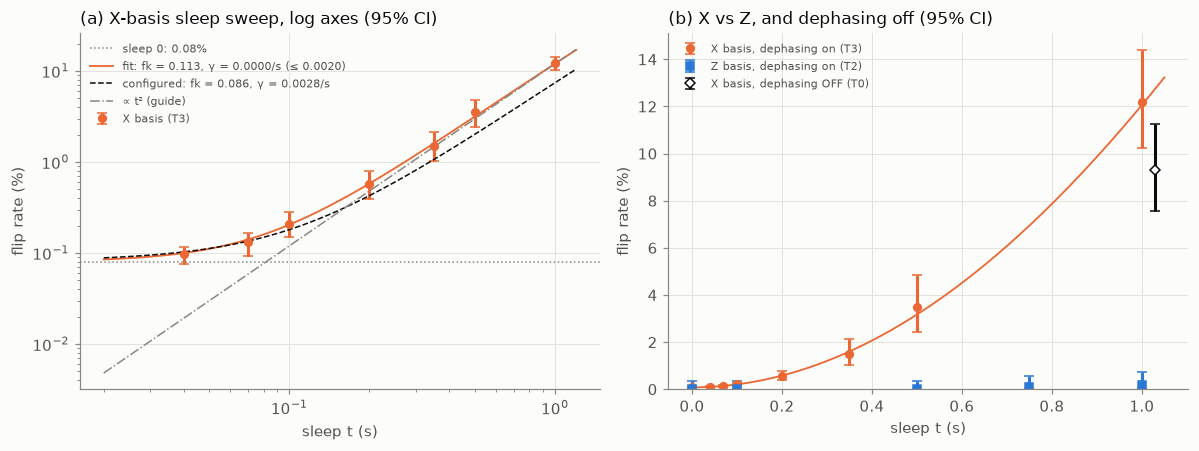

In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
t3 = sorted((sleep[n], n) for n in rows if rows[n]["test"] == "T3")
tx = np.array([t for t, _ in t3]); P3 = np.array([pt(n) for _, n in t3]).T
ts = np.geomspace(0.02, 1.2, 200); tl = np.linspace(0, 1.05, 200)
fitc = lambda t: oplus(fit["floor"], model(t, fit["gamma"], fit["fk"]))
conf = lambda t: oplus(fit["floor"], model(t, fit["configured"]["gamma"], fit["configured"]["fk"]))
lab_fit = f"fit: fk = {fit['fk']:.3f}, γ = {fit['gamma']:.4f}/s (≤ {fit['gamma_68'][1]:.4f})"
lab_conf = f"configured: fk = {fit['configured']['fk']}, γ = {fit['configured']['gamma']}/s"
m = tx > 0
a.errorbar(tx[m], 100 * P3[0][m], yerr=100 * P3[1:, m], fmt="o", color=P.SERIES[1], capsize=3, label="X basis (T3)")
a.axhline(100 * fit["floor"], color=P.MUTED, lw=1, ls=":", label=f"sleep 0: {100 * fit['floor']:.2f}%")
a.plot(ts, 100 * fitc(ts), color=P.SERIES[1], lw=1.2, label=lab_fit)
a.plot(ts, 100 * conf(ts), color=P.INK, lw=1, ls="--", label=lab_conf)
a.plot(ts, 100 * 0.12 * ts ** 2, color=P.MUTED, lw=1, ls="-.", label="∝ t² (guide)")
a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("sleep t (s)"); a.set_ylabel("flip rate (%)")
a.set_title("(a) X-basis sleep sweep, log axes (95% CI)", loc="left"); a.legend(fontsize=7.5)
b.errorbar(tx, 100 * P3[0], yerr=100 * P3[1:], fmt="o", color=P.SERIES[1], capsize=3, label="X basis, dephasing on (T3)")
b.plot(tl, 100 * fitc(tl), color=P.SERIES[1], lw=1.2)
t2 = sorted((sleep[n], n) for n in rows if rows[n]["test"] == "T2"); P2 = np.array([pt(n) for _, n in t2]).T
b.errorbar([t for t, _ in t2], 100 * P2[0], yerr=100 * P2[1:], fmt="s", color=P.SERIES[0], capsize=3, label="Z basis, dephasing on (T2)")
p0 = pt("T0_X_sleep1_off")
b.errorbar([1.03], [100 * p0[0]], yerr=[[100 * p0[1]], [100 * p0[2]]], fmt="D", color=P.INK, mfc="white", capsize=3,
           label="X basis, dephasing OFF (T0)")
b.set_xlabel("sleep t (s)"); b.set_ylabel("flip rate (%)"); b.set_ylim(bottom=0)
b.set_title("(b) X vs Z, and dephasing off (95% CI)", loc="left"); b.legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
P.save(fig, "18_idle_tests_h2_1e_1")

**Reading.**
- *T3:* the X error grows as t² (slope 2 in (a)); the fit needs no linear term (γ consistent with
  0, below ~0.002/s) and gives fk ≈ 0.113, above the configured 0.086. The configured curve
  (dashed) lies below every point from 0.2 s on.
- *T2:* in the Z basis sleep gives ≤ 0.2% up to 1 s, against 12% in X: sleep is almost pure
  dephasing.
- *T0:* with both dephasing flags off, sleep 1 s still gives 9.3%, not ~0. The flags remove only
  part of the sleep error (12.2% → 9.3%); most of it is not switched off by them.

## T4, T5a, T5: idling inside circuits, compared with sleep

Each bar is a flip rate with its 95% CI. In (a) and (c) the "off" runs are the same programs with
the dephasing flags off; their difference is the part those flags control. The derived times
use the T3 fit to turn that difference into seconds of sleep.

{'T4': {'idle_part_L64': 0.0005, 'se': 0.0006121172273347647, 'seconds_per_layer': 0.0009877634745670276, 'seconds_per_layer_upper_2se': 0.0018346566762944203}, 'T5': {'idle_part': 0.0045, 'se': 0.0009330979986046481, 'rounds': 5, 'seconds_per_round': 0.037955459105781894, 'seconds_per_round_upper_2se': 0.04515892708300477}, 'T5a': {'observed': 0.00825, 'fitted_concurrent': 0.008588048188518676, 'fitted_serial': 0.12060912056159852}}


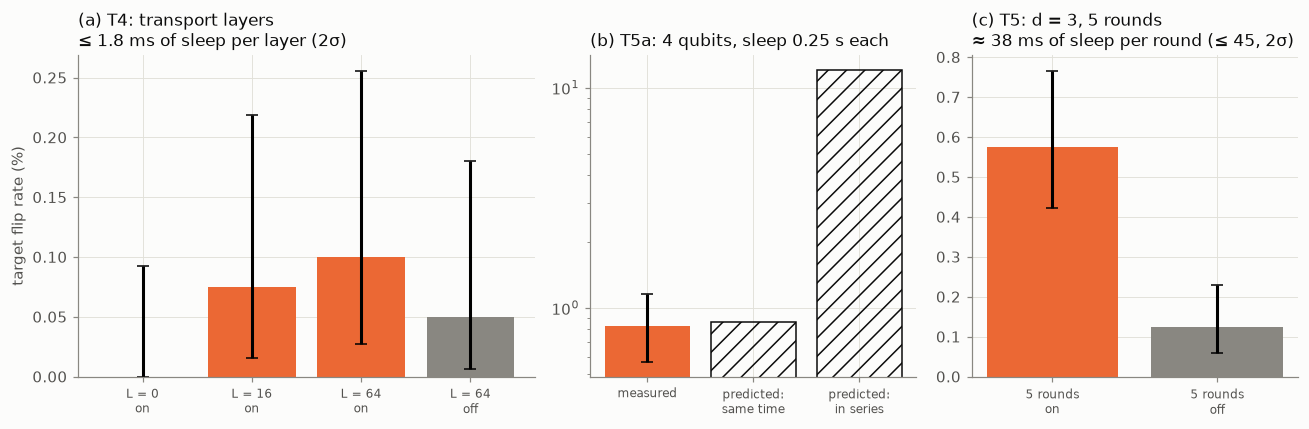

In [4]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
def bars(ax, names, labels, colors):
    v = np.array([pt(n) for n in names]).T
    ax.bar(range(len(names)), 100 * v[0], yerr=100 * v[1:], color=colors, capsize=4)
    ax.set_xticks(range(len(names)), labels, fontsize=8)
bars(a, ["T4_transport_L0_on", "T4_transport_L16_on", "T4_transport_L64_on", "T4_transport_L64_off"],
     ["L = 0\non", "L = 16\non", "L = 64\non", "L = 64\noff"], [P.SERIES[1]] * 3 + [P.MUTED])
d4 = der["T4"]
a.set_title(f"(a) T4: transport layers\n≤ {1e3 * d4['seconds_per_layer_upper_2se']:.1f} ms of sleep per layer (2σ)", loc="left")
a.set_ylabel("target flip rate (%)")
c5 = der["T5a"]
v = pt("T5a_sleep_each_0p25")
b.bar([0], [100 * v[0]], yerr=[[100 * v[1]], [100 * v[2]]], color=P.SERIES[1], capsize=4)
b.bar([1, 2], [100 * c5["fitted_concurrent"], 100 * c5["fitted_serial"]], color="none", edgecolor=P.INK, hatch="//")
b.set_xticks([0, 1, 2], ["measured", "predicted:\nsame time", "predicted:\nin series"], fontsize=8)
b.set_yscale("log"); b.set_title("(b) T5a: 4 qubits, sleep 0.25 s each", loc="left")
bars(c, ["T5_rounds5_on", "T5_rounds5_off"], ["5 rounds\non", "5 rounds\noff"], [P.SERIES[1], P.MUTED])
d5 = der["T5"]
c.set_title(f"(c) T5: d = 3, 5 rounds\n≈ {1e3 * d5['seconds_per_round']:.0f} ms of sleep per round (≤ {1e3 * d5['seconds_per_round_upper_2se']:.0f}, 2σ)", loc="left")
for ax in (a, b, c): ax.set_ylim(bottom=0 if ax is not b else None)
fig.tight_layout()
print({k: der[k] for k in der})
P.save(fig, "18_idle_tests_h2_1e_2")

**Reading.**
- *T4:* 64 transport layers add almost nothing (0.10% on, 0.05% off, 0 at L = 0): one layer is
  worth ≲ 1.8 ms of sleep (central ~1 ms).
- *T5a:* four sleeps of 0.25 s on four different qubits give what one 0.25 s sleep gives, not
  what 1 s gives: sleeps on different qubits overlap in time.
- *T5:* 5 rounds of d = 3 extraction give 0.58% on the waiting targets with dephasing on and
  0.13% with it off; through the T3 curve that is ~38 ms of sleep per round (≤ 45 ms, 2σ).
- *Caveat (from T0):* the "off" runs keep the part of the idle error that the flags do not
  control, so (a) and (c) measure only the flag-controlled part. Through the quadratic curve,
  that part would correspond to a somewhat longer time.